# ¿Qué operadores de CallMeMaybe trabajan mal?

**Proyecto final · Análisis de datos · TripleTen · Octubre 2026** — Angel Regino

**Objetivo:** darle a los supervisores de CallMeMaybe una lista de operadores ineficaces y comprobar si el tiempo de espera de los clientes depende de su tarifa (A, B o C).

**Presentación (PDF):** https://drive.google.com/file/d/1NGCsrrsiIfwrT_E3yZlvnLIAu1Sz1i00/view?usp=sharing


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as st

calls = pd.read_csv('/datasets/telecom_dataset_us.csv')
clients = pd.read_csv('/datasets/telecom_clients_us.csv')

calls.info()
clients.info()
print(calls.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53902 entries, 0 to 53901
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              53902 non-null  int64  
 1   date                 53902 non-null  object 
 2   direction            53902 non-null  object 
 3   internal             53785 non-null  object 
 4   operator_id          45730 non-null  float64
 5   is_missed_call       53902 non-null  bool   
 6   calls_count          53902 non-null  int64  
 7   call_duration        53902 non-null  int64  
 8   total_call_duration  53902 non-null  int64  
dtypes: bool(1), float64(1), int64(4), object(3)
memory usage: 3.3+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      732 non-null    int64 
 1   tariff_plan  732 non-null    object
 2 


## Hallazgos iniciales

**Dataset calls (53 902 registros):**
- operator_id tiene ~15% de valores nulos (8 172). Estas filas se
  eliminarán, ya que sin saber qué operador atendió la llamada no es
  posible atribuirle eficiencia o ineficiencia. Quedan 45 730 registros.
- internal tiene 117 valores nulos (0.2%). Se eliminarán, ya que es
  una columna True/False y su eliminación no tendrá un impacto
  representativo.
- operator_id es de tipo float; se convertirá a entero.
- date es de tipo texto e incluye zona horaria (+03:00); se convertirá
  a fecha.

**Dataset clients (732 registros):**
- No tiene valores nulos.
- date_start es de tipo texto; se convertirá a fecha.

In [ ]:
#eliminar los nulos en operator_id e internal
calls = calls.dropna(subset=["operator_id", "internal"])

#operator_id a entero

calls["operator_id"]= calls["operator_id"].astype(int)

#poniendo las fechas en su formato correcto

calls['date'] = pd.to_datetime(calls['date']).dt.tz_localize(None)
clients['date_start'] = pd.to_datetime(clients['date_start'])

# 3. Duplicados en ambos datasets
print('Duplicados en CALLS:', calls.duplicated().sum())
print('Duplicados en CLIENTS:', clients.duplicated().sum())

Duplicados en CALLS: 4179
Duplicados en CLIENTS: 0


In [ ]:
#ELIMINAR DUPLICADOS
calls = calls.drop_duplicates()
print('Duplicados despues de eliminarlos en CALLS:', calls.duplicated().sum())


Duplicados despues de eliminarlos en CALLS: 0


In [ ]:
#Crear columnas nuevas:
calls["tiempo_espera"]=  calls["total_call_duration"] - calls["call_duration"]
calls["espera_promedio"] = calls["tiempo_espera"] / calls["calls_count"]

In [ ]:
calls["espera_promedio"].describe()

count    41491.000000
mean        16.541547
std         11.948783
min          0.000000
25%          8.500000
50%         14.666667
75%         21.720000
max        451.203883
Name: espera_promedio, dtype: float64

In [ ]:
calls["call_duration"].describe()

count     41491.000000
mean       1010.940011
std        4066.666485
min           0.000000
25%           0.000000
50%         106.000000
75%         772.000000
max      144395.000000
Name: call_duration, dtype: float64

In [ ]:
np.percentile(calls["espera_promedio"], [90,95,99])

array([31.        , 37.81666667, 56.5       ])

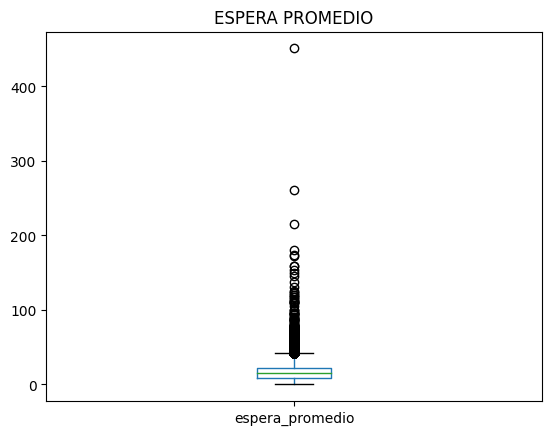

In [ ]:
#valores atipicos
calls["espera_promedio"].plot(kind="box")
plt.title("ESPERA PROMEDIO")
plt.show()

## Observaciones: distribuciones
- Tras eliminar nulos y 4 179 duplicados, quedan 41 491 registros.
- espera_promedio (segundos de espera por llamada): la mediana es de
  14.7 s, el percentil 99 es de 56.5 s y el máximo llega a 451 s.
- El boxplot muestra valores atípicos con esperas muy largas. No se
  eliminarán, ya que pueden ser reales y son justamente los que
  podrían señalar a los operadores

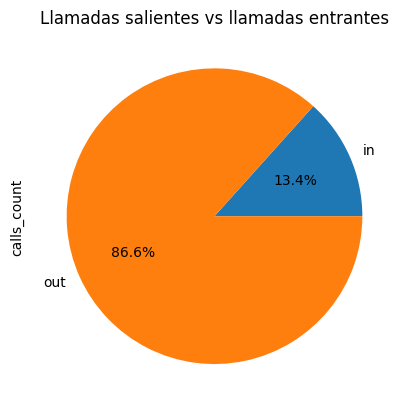

In [ ]:
#IN VS OUT
calls_direction = calls.groupby("direction")["calls_count"].sum().plot(kind='pie', autopct='%1.1f%%')
plt.title("Llamadas salientes vs llamadas entrantes")
plt.show()

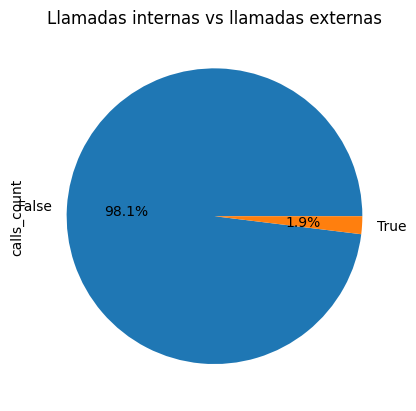

In [ ]:


internal_vs_external = calls.groupby("internal")["calls_count"].sum().plot(kind='pie', autopct='%1.1f%%')
plt.title("Llamadas internas vs llamadas externas")
plt.show()




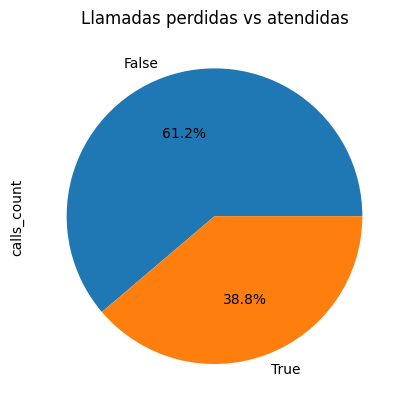

In [ ]:
misses_vs_answered  = calls.groupby("is_missed_call")["calls_count"].sum().plot(kind='pie', autopct='%1.1f%%')
plt.title("Llamadas perdidas vs atendidas")
plt.show()



## Observaciones: proporciones
- El 86.6% de las llamadas son salientes y solo el 13.4% entrantes.
- El 98.1% de las llamadas son externas; las internas son mínimas.
- El 38.8% de las llamadas son perdidas, una proporción alta. Sin
  embargo, incluye llamadas salientes no contestadas por el cliente,
  que no dependen del operador. Por eso, para medir eficiencia solo
  se considerarán las llamadas entrantes perdidas.

In [ ]:
#CARGA DE LLAMADAS POR OPERADOR
carga_por_operador = calls.groupby("operator_id")["calls_count"].sum()
carga_por_operador.describe()

count     1092.000000
mean       642.934982
std       2889.647014
min          1.000000
25%         10.000000
50%         72.000000
75%        493.750000
max      60221.000000
Name: calls_count, dtype: float64

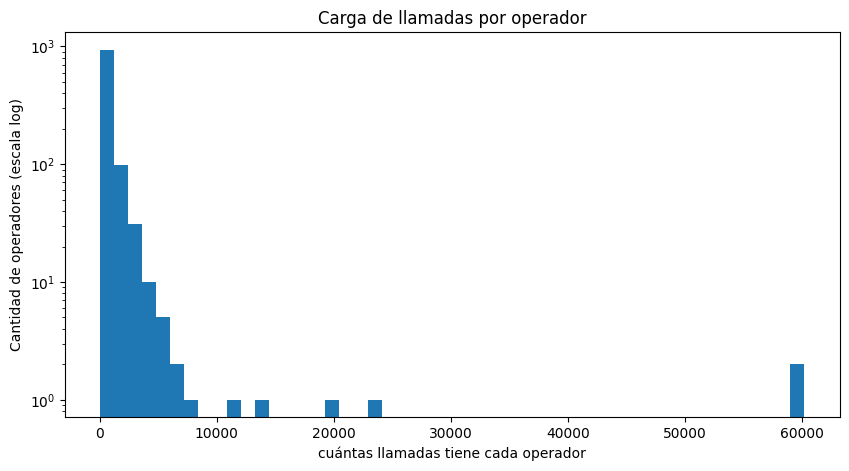

In [ ]:
carga_por_operador.plot(kind='hist', bins=50, logy=True, figsize=(10, 5))
plt.title('Carga de llamadas por operador')
plt.xlabel('cuántas llamadas tiene cada operador')
plt.ylabel('Cantidad de operadores (escala log)')
plt.show()

## Observaciones: carga por operador
- Hay 1 092 operadores. La carga es muy desigual: el 25% tiene 10
  llamadas o menos, la mediana es de 72 y unos pocos superan las
  10 000 (dos llegan a ~60 000).
- Evaluar a operadores con muy pocas llamadas puede dar resultados
  poco confiables, por lo que se definirá un mínimo de llamadas para
  incluirlos en la evaluación de eficiencia.

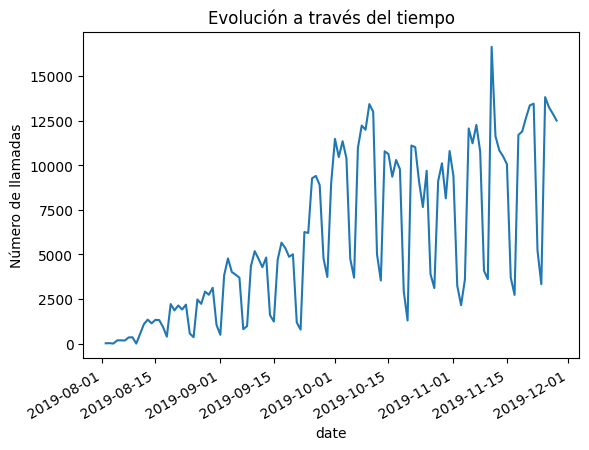

In [ ]:
evolución_tiempo  = calls.groupby("date")["calls_count"].sum().plot(kind="line")
plt.title("Evolución a través del tiempo")
plt.ylabel('Número de llamadas')
plt.show()

In [ ]:
print("fecha minima",calls["date"].min())
print("fecha maxima",calls["date"].max())

fecha minima 2019-08-02 00:00:00
fecha maxima 2019-11-28 00:00:00


## Observaciones: evolución en el tiempo
- Los datos van de agosto a noviembre de 2019.
- El número de llamadas diarias crece de forma sostenida, de casi
  0 a cerca de 12 500, lo que indica que el servicio gana clientes.
- Se observan caídas periódicas, probablemente fines de semana,
  cuando hay menos actividad.


In [ ]:
#LLAMADAS ENTRANTES
incoming = calls[calls["direction"]== "in"]

operator_in_calls = incoming.groupby("operator_id")["calls_count"].sum()

# Llamadas entrantes PERDIDAS por operador
missed = incoming[incoming['is_missed_call'] == True]

operator_missed = missed.groupby('operator_id')['calls_count'].sum()



In [ ]:
missed_rate = pd.DataFrame({'total_in': operator_in_calls, 'missed': operator_missed}).fillna(0)
missed_rate["pct_missed"]= missed_rate["missed"]/missed_rate["total_in"]
missed_rate.describe()

,total_in,missed,pct_missed
count,754.000000,754.000000,754.000000
mean,124.326260,1.226790,0.017569
std,356.294091,3.796661,0.065327
min,1.000000,0.000000,0.000000
25%,4.000000,0.000000,0.000000
50%,17.000000,0.000000,0.000000
75%,78.750000,1.000000,0.006817
max,4766.000000,52.000000,1.000000


- Para evaluar la eficiencia solo se consideran operadores con al
  menos 17 llamadas entrantes (la mediana), ya que con muy pocas
  llamadas su porcentaje de perdidas no es confiable.

In [ ]:

missed_rate = missed_rate[missed_rate["total_in"]>=17]
operator_wait = incoming.groupby("operator_id")["tiempo_espera"].sum()
missed_rate['wait_avg'] = operator_wait / operator_in_calls
missed_rate["wait_avg"].describe()

count    380.000000
mean      16.140197
std        9.848521
min        0.683673
25%        9.049342
50%       13.920000
75%       20.929217
max       50.958333
Name: wait_avg, dtype: float64

## Observaciones: métricas 1 y 2
- 754 operadores reciben llamadas entrantes. La mitad no pierde
  ninguna llamada, pero algunos llegan al 100% de perdidas, casi
  siempre con muy pocas llamadas.
- Tras aplicar el mínimo de 17 llamadas entrantes, quedan 380
  operadores para evaluar.
- Tiempo de espera promedio por llamada entrante: la mediana es de
  13.9 s, el 75% de los operadores está por debajo de 21 s y el
  máximo llega a 51 s.

In [ ]:
#LLAMADAS SALIENTES
outgoing = calls[calls["direction"]== "out"]
operator_out = outgoing.groupby("operator_id")["calls_count"].sum()
missed_rate["out_calls"] = operator_out
missed_rate['out_calls'] = missed_rate['out_calls'].fillna(0)
missed_rate.describe()

,total_in,missed,pct_missed,wait_avg,out_calls
count,380.000000,380.000000,380.000000,380.000000,380.000000
mean,241.600000,2.328947,0.016185,16.140197,813.250000
std,473.707516,5.103127,0.036343,9.848521,4400.401088
min,17.000000,0.000000,0.000000,0.683673,0.000000
25%,32.000000,0.000000,0.000000,9.049342,9.750000
50%,77.500000,1.000000,0.003628,13.920000,137.000000
75%,229.750000,2.000000,0.017376,20.929217,556.000000
max,4766.000000,52.000000,0.388889,50.958333,58977.000000


In [ ]:
(missed_rate['out_calls'] == 0).sum()

74

## Observaciones: tabla de evaluación (380 operadores)
- % de perdidas (pct_missed): la mediana es de 0.4% y el 75% de los
  operadores pierde menos del 1.7%; el máximo llega al 38.9%.
- Tiempo de espera (wait_avg): mediana de 13.9 s, el 75% está por
  debajo de 21 s y el máximo es de 51 s.
- Llamadas salientes (out_calls): la mediana es de 137, pero la
  distribución es muy desigual (máximo de 58 977). Hay 74
  operadores con 0 salientes, que no se evaluarán en esta métrica
  porque su rol parece ser solo recibir llamadas.

In [ ]:
limit_missed = missed_rate["pct_missed"].quantile(0.90)
limit_wait = missed_rate["wait_avg"].quantile(0.90)
limit_out = missed_rate[missed_rate["out_calls"]> 0]["out_calls"].quantile(0.10)

In [ ]:
print('Límite % perdidas:', limit_missed)
print('Límite espera:', limit_wait)
print('Límite salientes:', limit_out)

Límite % perdidas: 0.04184782608695656
Límite espera: 28.993351937984528
Límite salientes: 16.0


## Límites de ineficacia (percentiles)
- % de perdidas: más del 4.2% (percentil 90).
- Tiempo de espera: más de 29 s por llamada (percentil 90).
- Llamadas salientes: menos de 16 (percentil 10, solo entre
  operadores que sí realizan llamadas salientes).
- Se usan percentiles para marcar como "malo" al 10% de operadores
  con peor desempeño en cada métrica, en lugar de elegir límites
  arbitrarios.

In [ ]:
missed_rate['bad_missed'] = missed_rate['pct_missed'] > limit_missed
missed_rate['bad_wait'] = missed_rate['wait_avg'] > limit_wait
missed_rate['bad_out'] = (missed_rate['out_calls'] > 0) & (missed_rate['out_calls'] < limit_out)

In [ ]:
missed_rate["num_flags"] = (missed_rate['bad_missed'].astype(int) + missed_rate['bad_wait'].astype(int) + missed_rate['bad_out'].astype(int))


In [ ]:
#confrimar que funciono
missed_rate["num_flags"].value_counts()

0    293
1     69
2     18
Name: num_flags, dtype: int64

In [ ]:
#creamos la columna para mostrar los ineficientes
missed_rate["ineficaz"] = missed_rate["num_flags"] >= 2

In [ ]:

#cuantos hay?
missed_rate["ineficaz"].value_counts()


False    362
True      18
Name: ineficaz, dtype: int64

In [ ]:
trabajadores_ineficientes = missed_rate[missed_rate['ineficaz'] == True].sort_values('pct_missed', ascending=False)
print(trabajadores_ineficientes)


             total_in  missed  pct_missed   wait_avg  out_calls  bad_missed  \
operator_id                                                                   
937368             22     4.0    0.181818  24.136364       10.0        True   
944226            180    30.0    0.166667  42.661111      109.0        True   
905862            102    15.0    0.147059  11.421569        1.0        True   
926872             24     3.0    0.125000   0.791667        7.0        True   
911102             27     3.0    0.111111  30.444444        0.0        True   
944216            234    24.0    0.102564  35.658120      133.0        True   
911142             20     2.0    0.100000  46.150000        0.0        True   
944222            184    17.0    0.092391  33.989130      344.0        True   
944220            263    18.0    0.068441  36.163498      221.0        True   
944218            245    15.0    0.061224  36.718367      164.0        True   
924954             19     1.0    0.052632  31.789474

## Operadores ineficaces
- Un operador se considera ineficaz si tiene valores "malos" en al
  menos 2 de sus métricas.
- De 380 operadores evaluados: 293 no tienen ninguna alerta, 69
  tienen una y 18 tienen dos. Ninguno falla en las tres.
- Resultado: 18 operadores ineficaces (4.7%), que deberían recibir
  seguimiento por parte de los supervisores.

## PLAN A SEGUIR
- H0: El tiempo de espera promedio es igual entre las tarifas.
- H1: El tiempo de espera promedio es diferente entre las tarifas.
- alfa = 0.05

In [ ]:
incoming_tariff = incoming.merge(clients, on= "user_id",how= "left")
wait_avg_tariff = incoming_tariff.groupby("tariff_plan")["espera_promedio"].mean()
print(wait_avg_tariff.head())

tariff_plan
A    14.979318
B    18.742028
C    15.634946
Name: espera_promedio, dtype: float64


In [ ]:
wait_A = incoming_tariff[incoming_tariff['tariff_plan'] == 'A']['espera_promedio']
wait_B = incoming_tariff[incoming_tariff['tariff_plan'] == 'B']['espera_promedio']
wait_C = incoming_tariff[incoming_tariff['tariff_plan'] == 'C']['espera_promedio']

In [ ]:
print('A vs B:', st.mannwhitneyu(wait_A, wait_B).pvalue)
print('A vs C:', st.mannwhitneyu(wait_A, wait_C).pvalue)
print('B vs C:', st.mannwhitneyu(wait_B, wait_C).pvalue)

A vs B: 1.2253275495394413e-44
A vs C: 1.5487483860350177e-13
B vs C: 1.6613602285437864e-15


## Resultados de la prueba de hipótesis
- Se usó la prueba de Mann-Whitney, ya que el tiempo de espera
  presenta valores extremos.
- En las tres comparaciones (A vs B, A vs C, B vs C) el p-value es
  mucho menor a 0.05 (y a 0.017 con la corrección de Bonferroni),
  por lo que se rechaza H0.
- El tiempo de espera es significativamente diferente entre las
  tarifas. Los clientes de la tarifa B esperan más (18.7 s) que los
  de A (15.0 s) y C (15.6 s).

# Conclusiones generales
- Tras la limpieza (nulos y 4 179 duplicados) se trabajó con 41 491
  registros. El servicio crece de forma sostenida entre agosto y
  noviembre de 2019; el 86.6% de las llamadas son salientes.
- Se evaluaron 380 operadores con al menos 17 llamadas entrantes
  usando 3 métricas: % de entrantes perdidas, tiempo de espera y
  número de llamadas salientes.
- Con límites basados en percentiles, se identificaron 18 operadores
  ineficaces (4.7%), que fallan en 2 de sus métricas.
- El tiempo de espera es significativamente diferente entre tarifas:
  los clientes de la tarifa B esperan más (18.7 s) que los de A y C.

## Recomendaciones
- Dar seguimiento y capacitación a los 18 operadores ineficaces.
- Revisar la asignación de operadores para clientes de la tarifa B.
- Incorporar estas métricas en el panel de supervisores para
  monitorearlas de forma continua.

## Fuentes
1. pandas: groupby — https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html
   Agrupar llamadas por operador, fecha y tarifa.
2. pandas: merge — https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html
   Unir llamadas con la tarifa de cada cliente.
3. pandas: quantile — https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html
   Definir los límites de ineficacia con percentiles.
4. pandas: tz_localize — https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.tz_localize.html
   Quitar la zona horaria de la columna de fechas.
5. pandas: plot — https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.html
   Crear histogramas, pasteles y gráficos de líneas.
6. SciPy: mannwhitneyu — https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html
   Comparar el tiempo de espera entre tarifas.
7. Corrección de Bonferroni — https://en.wikipedia.org/wiki/Bonferroni_correction
   Ajustar el nivel de significancia al hacer varias pruebas.